# StyleVector — End-Term Extension (FIXED v2)

**What was wrong with v1 (why you saw no improvement)** — all fixed below:

1. **Style-agnostic responses `y_hat` were polluted.** LLaMA-2-chat answers start with *"Sure! Here's a headline…"* and were cut at 40 tokens mid-sentence. So every delta `a_p - a_n` encoded *"terse+complete vs chatty+truncated"*, not user style. -> `clean_output()` now strips preambles/quotes, applied to `y_hat`, the baseline and every steered output (so the comparison stays fair).
2. **LaMP_7 (tweets) history was garbage.** Every history item used the constant input `"Write a short tweet."`, so `y_hat` was nearly identical for all items. -> a neutral rewrite of each tweet is now generated and used as `x_i`.
3. **Train/inference mismatch.** Activations were taken on raw `"{x} {y}"` text, but steering happens inside the chat template. -> activations now use the *same* chat-templated prompt (`[INST] prompt [/INST] response`), and history prompts match LaMP's real query wording.
4. **Norm-preserving can't help at the alpha you used.** alpha=0.25-0.5 means the perturbation is a tiny fraction of `||h||`, so rescaling to the original norm is a near no-op. NP only matters at *large* alpha. -> alpha is now tuned **per condition** on held-out tuning users (NP gets a larger grid). A diagnostic cell prints `alpha*||s|| / ||h||` so you can see this.
5. **The per-user PCA vector was a weak design.** With only 15-60 history items in a 4096-d space, per-user top-k PCs capture content noise, not the consistent style direction (the paper's own Fig. 6 shows PCA < Mean). Kept as `pca_orig` (negative control). **New multi-component method (`shared`)**: learn a *shared* top-r style basis from the deltas of ALL users (hundreds of users -> a well-estimated subspace; label-free, uses histories only), then represent each user as coefficients on that basis: `s_u = sum_j <v_j, m_u> v_j` (leave-one-out basis, so a user never helps build their own basis). This denoises the user's mean difference. Whether it helps on real data depends on users sharing low-dimensional style structure (paper Fig. 8 suggests they do) -- the bootstrap cell tells you.
6. **Steering only touched the last prompt token + generated tokens.** Now steers all prompt tokens (except BOS) + generated tokens (paper Fig. 6: more tokens -> larger gain).
7. **Statistics.** Differences of 1-3% on ~300 users are noise. Added paired-bootstrap CIs.

2x2 ablation: `mean` / `mean_np` (single) vs `shared` / `shared_np` (multi-component) -> `shared_np` is the full method.

## Part 0 — Environment Setup

In [1]:
# Cell 0.1 — Working directory (local lab PC)
import os
PROJECT_DIR = os.path.expanduser('~/stylevector_project')
os.makedirs(PROJECT_DIR, exist_ok=True)
os.chdir(PROJECT_DIR)
print("Working directory:", os.getcwd())

Working directory: /home/user/stylevector_project


In [2]:
# Cell 0.2 — Install dependencies
!pip install -q torch transformers accelerate bitsandbytes rouge-score nltk huggingface_hub --upgrade


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [3]:
# Cell 0.3 — NLTK data (with fallback if blocked)
import os
os.environ["NLTK_ALLOW_PROXIED_URLOPEN"] = "1"
import nltk
try:
    nltk.pathsec.ALLOW_PROXIED_FETCH = True
except AttributeError:
    pass

NLTK_OK = True
try:
    nltk.download('wordnet', quiet=True)
    nltk.download('punkt', quiet=True)
    nltk.download('punkt_tab', quiet=True)
    nltk.download('omw-1.4', quiet=True)
    from nltk import word_tokenize
    from nltk.translate.meteor_score import meteor_score
    _ = word_tokenize("test sentence")
    _ = meteor_score([["test", "sentence"]], ["test", "sentence"])
    print("NLTK data OK -- using real METEOR + real tokenizer.")
except Exception as e:
    NLTK_OK = False
    print(f"NLTK data unavailable ({e}). Falling back to unigram-F1 METEOR proxy.")


/home/user/stylevector_env/lib/python3.12/site-packages/nltk/downloader.py:1554: UserWarning: NLTK will not authorize the non-private download directory '/home/user/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(
/home/user/stylevector_env/lib/python3.12/site-packages/nltk/downloader.py:980: UserWarning: NLTK will not authorize the non-private download directory '/home/user/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force, (), extract):


NLTK data unavailable (
**********************************************************************
  Resource 'punkt_tab' not found.
  Please use the NLTK Downloader to obtain the resource:

  >>> import nltk
  >>> nltk.download('punkt_tab')

  For more information see: https://www.nltk.org/data.html

  Attempted to load 'tokenizers/punkt_tab/english/'

  Refused, writable by other accounts (a file planted or
  rewritten there would be loaded as trusted data):
    - '/home/user/nltk_data'
  Make each one private to its owner, e.g.:
    chmod go-w '/home/user/nltk_data'
  then download the packages it holds again (force=True): a
  file changed while it was writable keeps the change.

  Searched in:
    - '/home/user/nltk_data'
    - '/home/user/stylevector_env/nltk_data'
    - '/home/user/stylevector_env/share/nltk_data'
    - '/home/user/stylevector_env/lib/nltk_data'
    - '/usr/share/nltk_data'
    - '/usr/local/share/nltk_data'
    - '/usr/lib/nltk_data'
    - '/usr/local/lib/nltk_data'

[nltk_data] Refusing to install into '/home/user/nltk_data': it is
[nltk_data]     writable by, or owned by, another account, so a file
[nltk_data]     swapped in during the install would be installed as
[nltk_data]     trusted data. Make it private to its owner (chmod
[nltk_data]     go-w).
[nltk_data] Refusing to install into '/home/user/nltk_data': it is
[nltk_data]     writable by, or owned by, another account, so a file
[nltk_data]     swapped in during the install would be installed as
[nltk_data]     trusted data. Make it private to its owner (chmod
[nltk_data]     go-w).
[nltk_data] Refusing to install into '/home/user/nltk_data': it is
[nltk_data]     writable by, or owned by, another account, so a file
[nltk_data]     swapped in during the install would be installed as
[nltk_data]     trusted data. Make it private to its owner (chmod
[nltk_data]     go-w).
[nltk_data] Refusing to install into '/home/user/nltk_data': it is
[nltk_data]     writable by, or owned by, another acco

In [4]:
# Cell 0.4 — Imports
import json, time, re, random
from pathlib import Path

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import logging
logging.getLogger("transformers").setLevel(logging.ERROR)

plt.rcParams["figure.dpi"] = 110
RNG_SEED = 42
print("Imports OK. CUDA available:", torch.cuda.is_available())

Imports OK. CUDA available: True


/home/user/stylevector_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Part 1 — Download & Load LaMP (dev split)

In [5]:
%%writefile download_lamp.sh
#!/usr/bin/env bash
set -euo pipefail
OUT_DIR="${1:-./data/lamp}"
BASE_URL="https://ciir.cs.umass.edu/downloads/LaMP"

declare -A TASKS=(
  [LaMP_4]="News Headline Generation"
  [LaMP_5]="Scholarly Title Generation"
  [LaMP_7]="Tweet Paraphrasing"
)
SPLITS=(train dev test)
FILE_TYPES=(questions outputs)

for task in "${!TASKS[@]}"; do
  echo "== ${task}: ${TASKS[$task]} =="
  for split in "${SPLITS[@]}"; do
    mkdir -p "${OUT_DIR}/${task}/${split}"
    for ftype in "${FILE_TYPES[@]}"; do
      url="${BASE_URL}/${task}/${split}/${split}_${ftype}.json"
      out="${OUT_DIR}/${task}/${split}/${split}_${ftype}.json"
      if [ -f "${out}" ]; then
        echo "  [cached] ${out}"
        continue
      fi
      echo "  fetching ${url}"
      if curl -sSf --retry 3 --max-time 60 -o "${out}" "${url}"; then
        echo "    saved -> ${out}"
      else
        echo "    [skip] not publicly available: ${url}"
        rm -f "${out}"
      fi
    done
  done
done
echo "Done."


Overwriting download_lamp.sh


In [6]:
# Cell 1.2 — Run the download (idempotent, safe to re-run -- will mostly hit [cached])
!bash download_lamp.sh ./data/lamp
!ls -la ./data/lamp/LaMP_5/dev/

== LaMP_7: Tweet Paraphrasing ==
  [cached] ./data/lamp/LaMP_7/train/train_questions.json
  [cached] ./data/lamp/LaMP_7/train/train_outputs.json
  [cached] ./data/lamp/LaMP_7/dev/dev_questions.json
  [cached] ./data/lamp/LaMP_7/dev/dev_outputs.json
  [cached] ./data/lamp/LaMP_7/test/test_questions.json
  [cached] ./data/lamp/LaMP_7/test/test_outputs.json
== LaMP_4: News Headline Generation ==
  [cached] ./data/lamp/LaMP_4/train/train_questions.json
  [cached] ./data/lamp/LaMP_4/train/train_outputs.json
  [cached] ./data/lamp/LaMP_4/dev/dev_questions.json
  [cached] ./data/lamp/LaMP_4/dev/dev_outputs.json
  [cached] ./data/lamp/LaMP_4/test/test_questions.json
  [cached] ./data/lamp/LaMP_4/test/test_outputs.json
== LaMP_5: Scholarly Title Generation ==
  [cached] ./data/lamp/LaMP_5/train/train_questions.json
  [cached] ./data/lamp/LaMP_5/train/train_outputs.json
  [cached] ./data/lamp/LaMP_5/dev/dev_questions.json
  [cached] ./data/lamp/LaMP_5/dev/dev_outputs.json
  [cached] ./data/lamp/

In [7]:
%%writefile load_lamp_data.py
import json
from pathlib import Path
from typing import Optional

TASK_PROFILE_FIELDS = {
    "LaMP_4": ("text", "title"),
    "LaMP_5": ("abstract", "title"),
    "LaMP_7": (None, "text"),
}


def load_json(path: Path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


def build_gold_lookup(outputs_json: dict) -> dict:
    return {item["id"]: item["output"] for item in outputs_json["golds"]}


def make_synthetic_input(y_text: str) -> str:
    return "Write a short tweet."


def load_task_split(data_dir: Path, task: str, split: str,
                     max_users: Optional[int] = None,
                     max_history_per_user: Optional[int] = None,
                     min_history_len: int = 3):
    assert task in TASK_PROFILE_FIELDS, f"Unsupported task: {task}"
    input_field, output_field = TASK_PROFILE_FIELDS[task]

    q_path = data_dir / task / split / f"{split}_questions.json"
    o_path = data_dir / task / split / f"{split}_outputs.json"

    questions = load_json(q_path)
    gold_lookup = {}
    if o_path.exists():
        gold_lookup = build_gold_lookup(load_json(o_path))

    for q in questions:
        if q["profile"]:
            sample = q["profile"][0]
            print(f"[{task}/{split}] sample profile item keys: {list(sample.keys())}")
            if output_field not in sample:
                raise KeyError(f"Expected output field '{output_field}' not found in {sample}")
            break

    users = {}
    for q in questions:
        user_id = q["id"]
        history = []
        for item in q["profile"]:
            y_i = item.get(output_field)
            if y_i is None:
                continue
            x_i = item.get(input_field) if input_field is not None else make_synthetic_input(y_i)
            history.append((x_i, y_i))

        if len(history) < min_history_len:
            continue
        if max_history_per_user is not None:
            history = history[:max_history_per_user]

        gold = gold_lookup.get(user_id)
        if gold is None:
            continue

        users[user_id] = {"history": history, "query_input": q["input"], "query_gold": gold}
        if max_users is not None and len(users) >= max_users:
            break

    return users


Overwriting load_lamp_data.py


In [8]:
# Cell 1.4 — Load tasks. Eval users = same first-N as before; TUNE users are DISJOINT (used only to pick layer/alpha).
from load_lamp_data import load_task_split
from pathlib import Path

TASKS = ["LaMP_4", "LaMP_5", "LaMP_7"]
DATA_DIR = Path("./data/lamp")
MAX_HISTORY_PER_USER_BY_TASK = {"LaMP_4": 15, "LaMP_5": 15, "LaMP_7": 15}
N_EVAL_USERS_CAP = 300
N_TUNE_USERS = 30

eval_users, tune_users = {}, {}
for task in TASKS:
    cap = MAX_HISTORY_PER_USER_BY_TASK[task]
    pool = load_task_split(data_dir=DATA_DIR, task=task, split="dev",
                           max_users=None, max_history_per_user=cap, min_history_len=3)
    all_ids = list(pool.keys())
    random.Random(RNG_SEED).shuffle(all_ids)
    eval_ids = all_ids[:N_EVAL_USERS_CAP]
    tune_ids = all_ids[N_EVAL_USERS_CAP:N_EVAL_USERS_CAP + N_TUNE_USERS]
    eval_users[task] = {u: pool[u] for u in eval_ids}
    tune_users[task] = {u: pool[u] for u in tune_ids}
    print(f"{task}: pool={len(pool)} eval={len(eval_users[task])} tune={len(tune_users[task])}")
    ex = next(iter(eval_users[task].values()))
    print("   sample query_input:", repr(ex["query_input"][:150]))


[LaMP_4/dev] sample profile item keys: ['text', 'title', 'id']
LaMP_4: pool=1925 eval=300 tune=30
   sample query_input: 'Generate a headline for the following article: "I just don\'t feel welcome into that house," LeGarrette Blount said.'
[LaMP_5/dev] sample profile item keys: ['title', 'abstract', 'id']
LaMP_5: pool=2500 eval=300 tune=30
   sample query_input: 'Generate a title for the following abstract of a paper: The ageing population and shrinking pool of labor is posing a critical threat to sustainable e'
[LaMP_7/dev] sample profile item keys: ['text', 'id']
LaMP_7: pool=1500 eval=300 tune=30
   sample query_input: 'Paraphrase the following tweet without any explanation before or after it: @Funkybabygirl found it funny and expressed this by adding "lool" and two k'


## Part 2 — Load LLaMA-2-7B-chat (4-bit, same as midterm)

Requires a HuggingFace token with approved access to `meta-llama/Llama-2-7b-chat-hf`,
already cached via `huggingface-cli login` on this machine.

In [9]:
# Cell 2.1 — Clean up any stale GPU memory from a previous session first
import gc, torch
for var_name in ["model", "tokenizer"]:
    if var_name in dir():
        del globals()[var_name]
gc.collect()
torch.cuda.empty_cache()
if torch.cuda.is_available():
    print(f"GPU memory allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")
    print(f"GPU memory reserved:  {torch.cuda.memory_reserved()/1e9:.2f} GB")


GPU memory allocated: 0.00 GB
GPU memory reserved:  0.00 GB


In [10]:
# Cell 2.2 — Load tokenizer + model (4-bit NF4, matching the midterm run)
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

MODEL_NAME = "meta-llama/Llama-2-7b-chat-hf"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

quant_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=torch.float16,
    device_map="auto",
    quantization_config=quant_config,
)
model.eval()
model.generation_config.max_length = 1024

N_LAYERS = len(model.model.layers)
HIDDEN_DIM = model.config.hidden_size
print(f"Loaded {MODEL_NAME}")
print(f"Layers: {N_LAYERS} | Hidden dim: {HIDDEN_DIM}")
print(f"GPU memory allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")

Loading weights: 100%|███████████████████████| 291/291 [00:19<00:00, 14.73it/s]

Loaded meta-llama/Llama-2-7b-chat-hf
Layers: 32 | Hidden dim: 4096
GPU memory allocated: 4.19 GB


## Part 3 — Core machinery (fixed)

In [11]:
# Cell 3.1 — Prompt templates. Match LaMP's REAL query wording (colon, no quotes) so history prompts
# look like the evaluation prompts. >>> Compare with the "sample query_input" printed above and
# edit these lambdas if the wording differs. <<<
TASK_PROMPTS = {
    "LaMP_4": lambda t: f"Generate a headline for the following article: {t}",
    "LaMP_5": lambda t: f"Generate a title for the following abstract of a paper: {t}",
    "LaMP_7": lambda t: f"Paraphrase the following tweet without any explanation before or after it: {t}",
}
NEUTRAL_REWRITE = lambda t: ("Rewrite the following tweet in plain, neutral, formal English, keeping the meaning. "
                             f"Output only the rewritten text: {t}")

def truncate_words(s, n):
    w = s.split()
    return " ".join(w[:n])


In [12]:
# Cell 3.2 — Chat formatting, output cleaning, plain generation
def chat_prompt_text(prompt):
    try:
        return tokenizer.apply_chat_template([{"role": "user", "content": prompt}],
                                             add_generation_prompt=True, tokenize=False)
    except Exception:
        return f"<s>[INST] {prompt} [/INST]"

def build_input_ids(prompt):
    ids = tokenizer(chat_prompt_text(prompt), return_tensors="pt", add_special_tokens=False).input_ids
    return ids.to(model.device)

_PRE = re.compile(r"^\s*(?:sure|certainly|of course|okay|ok|absolutely|great|here(?:'s| is| are))\b[^:\n]*:\s*", re.I)
_PRE_LINE = re.compile(r"^(sure|certainly|of course|okay|absolutely|great|here)\b", re.I)

def clean_output(text):
    """Strip chatty preambles / wrapping quotes / trailing lines. Applied identically to ALL conditions."""
    t = _PRE.sub("", text.strip(), count=1)
    lines = [l.strip() for l in t.split("\n") if l.strip()]
    if not lines:
        return ""
    first = lines[0]
    if _PRE_LINE.match(first) and len(lines) > 1:
        first = lines[1]
    m = re.match(r'^["\u201c](.+?)["\u201d]\s*$', first)
    if m:
        first = m.group(1)
    return first.strip().strip('"\u201c\u201d').strip()

def generate_text(prompt, max_new_tokens=40, clean=True):
    input_ids = build_input_ids(prompt)
    with torch.no_grad():
        out = model.generate(input_ids, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tokenizer.eos_token_id)
    txt = tokenizer.decode(out[0][input_ids.shape[1]:], skip_special_tokens=True).strip()
    return clean_output(txt) if clean else txt

print(clean_output("Sure! Here's a headline for the article:\n\n\"Teen Safety Online: Tips for Parents\"\n\nI hope this helps"))
print(clean_output("Sure! Here's a title: Deep Nets for Vision"))


Teen Safety Online: Tips for Parents
Deep Nets for Vision


In [13]:
# Cell 3.3 — Activations at MANY layers in ONE forward pass, using the same chat-templated context as inference.
# hidden_states[l+1] == output of model.model.layers[l]  (what the steering hook modifies).
MAX_LEN = 700

@torch.no_grad()
def get_activations(prompt, response, layers):
    text = chat_prompt_text(prompt) + ((" " + response) if response else "")
    ids = tokenizer(text, return_tensors="pt", add_special_tokens=False).input_ids[:, :MAX_LEN].to(model.device)
    hs = model.model(input_ids=ids, output_hidden_states=True).hidden_states
    return {l: hs[l + 1][0, -1].float().cpu() for l in layers}


In [14]:
# Cell 3.4 — Contrastive deltas for ALL candidate layers at once (cached on disk per user).
DELTA_CACHE = Path("./delta_cache"); DELTA_CACHE.mkdir(exist_ok=True)
LAYERS = [16, 20]          # candidate steering layers (paper: middle-to-late layers work best)
assert max(LAYERS) < N_LAYERS - 1

def compute_user_deltas(uid, task, history, max_history, max_gen_tokens=40):
    cache = DELTA_CACHE / f"{task}_{uid}.pt"
    if cache.exists():
        d = torch.load(cache)
        if all(l in d for l in LAYERS):
            return {l: d[l].float() for l in LAYERS}
    prompt_fn = TASK_PROMPTS[task]
    per_layer = {l: [] for l in LAYERS}
    for x_i, y_i in history[:max_history]:
        if not y_i:
            continue
        y_i = truncate_words(y_i, 120)
        if task == "LaMP_7":      # no real input exists for tweets -> neutral rewrite of the tweet itself
            x_i = generate_text(NEUTRAL_REWRITE(y_i), max_new_tokens=60)
        if not x_i:
            continue
        prompt_i = prompt_fn(truncate_words(x_i, 250))
        y_hat = generate_text(prompt_i, max_new_tokens=max_gen_tokens)       # style-agnostic (cleaned)
        if not y_hat:
            continue
        a_p = get_activations(prompt_i, y_i, LAYERS)
        a_n = get_activations(prompt_i, y_hat, LAYERS)
        for l in LAYERS:
            per_layer[l].append(a_p[l] - a_n[l])
    if len(per_layer[LAYERS[0]]) == 0:
        return None
    out = {l: torch.stack(v) for l, v in per_layer.items()}
    torch.save({l: v.half() for l, v in out.items()}, cache)
    return out


In [15]:
# Cell 3.5 — Style vectors from the deltas
#   mean      : paper's Mean Difference (Eq. 7)                              [single vector]
#   pca_orig  : v1's per-user top-k PCA, sqrt(var)-weighted sum              [negative control]
#   shared    : mean difference projected on a SHARED top-r PCA style basis  [our multi-component vector]
#               basis = top-r right singular vectors of the matrix of all OTHER users' mean deltas (leave-one-out);
#               s_u = sum_j <v_j, m_u> v_j  (r coefficients per user); rescaled to ||m_u|| so alpha is comparable.
R_SHARED = 16
POOL = {}   # task -> {"uids": [...], "means": {layer: (n_users, d)}}

def build_vectors(deltas, k=3, pool_means=None, self_idx=None, r=R_SHARED):
    D = deltas.float(); m = D.mean(0); mn = m.norm().clamp(min=1e-8)
    out = {"mean": m}; info = {}
    if D.shape[0] >= 2 and k > 1:
        aug = torch.cat([D, -D], 0)
        _, S, Vt = torch.linalg.svd(aug, full_matrices=False)
        ke = min(k, Vt.shape[0]); V = Vt[:ke]
        ev = S[:ke] ** 2; ev = ev / (S ** 2).sum()
        sgn = torch.sign(V @ m); sgn[sgn == 0] = 1
        w = ev.sqrt(); w = w / w.sum()
        pca = ((w * sgn).unsqueeze(1) * V).sum(0)
        out["pca_orig"] = pca / pca.norm().clamp(min=1e-8) * mn
        info["explained"] = ev.tolist()
    else:
        out["pca_orig"] = m.clone()
    if pool_means is not None and pool_means.shape[0] > r + 1:
        M = pool_means.float()
        if self_idx is not None:
            M = torch.cat([M[:self_idx], M[self_idx + 1:]], 0)      # leave-one-out
        _, _, Vt = torch.linalg.svd(M, full_matrices=False)
        V = Vt[:r]
        sh = ((V @ m).unsqueeze(1) * V).sum(0)
        out["shared"] = sh / sh.norm().clamp(min=1e-8) * mn
        info["frac_norm_kept"] = float((V @ m).norm() / mn)
    else:
        out["shared"] = m.clone()
    cos = lambda a, b: float(torch.dot(a, b) / (a.norm() * b.norm() + 1e-8))
    info["cos_pca_mean"] = cos(out["pca_orig"], m); info["cos_shared_mean"] = cos(out["shared"], m)
    return out, info

def load_pool(task):
    users = {**eval_users[task], **tune_users[task]}
    uids, means = [], {l: [] for l in LAYERS}
    for uid, u in tqdm(users.items(), desc=f"deltas {task}"):
        d = compute_user_deltas(uid, task, u["history"], MAX_HISTORY_PER_USER_BY_TASK[task], MAX_GEN_TOKENS)
        if d is None: continue
        uids.append(uid)
        for l in LAYERS: means[l].append(d[l].mean(0))
    POOL[task] = {"uids": uids, "means": {l: torch.stack(v) for l, v in means.items()}}

def vectors_for_user(task, uid, d):
    idx = POOL[task]["uids"].index(uid)
    return {l: build_vectors(d[l], K_COMPONENTS, POOL[task]["means"][l], idx)[0] for l in LAYERS}


In [16]:
# Cell 3.6 — Steering hook (Eq. 11) + norm-preserving variant (Eq. 1 of the proposal), fp32 math.
# positions="all": every prompt token except BOS (prefill) + every generated token (decode steps are length 1).
def make_steering_hook(direction, alpha, norm_preserving=False, positions="all"):
    direction = direction.float()
    def hook(module, inp, output):
        is_t = isinstance(output, tuple)
        hs = output[0] if is_t else output
        h = hs.float().clone()
        sl = slice(1, None) if (h.shape[1] > 1 and positions == "all") else slice(-1, None)
        x = h[:, sl, :]
        new = x + alpha * direction.to(h.device)
        if norm_preserving:
            new = new * (x.norm(dim=-1, keepdim=True) / new.norm(dim=-1, keepdim=True).clamp(min=1e-6))
        h[:, sl, :] = new
        h = h.to(hs.dtype)
        return ((h,) + tuple(output[1:])) if is_t else h
    return hook

def generate_with_steering(prompt, layer, direction, alpha, norm_preserving=False, max_new_tokens=40, positions="all"):
    input_ids = build_input_ids(prompt)
    handle = model.model.layers[layer].register_forward_hook(
        make_steering_hook(direction, alpha, norm_preserving, positions))
    try:
        with torch.no_grad():
            out = model.generate(input_ids, max_new_tokens=max_new_tokens, do_sample=False,
                                 pad_token_id=tokenizer.eos_token_id)
    finally:
        handle.remove()
    return clean_output(tokenizer.decode(out[0][input_ids.shape[1]:], skip_special_tokens=True).strip())


In [17]:
# Cell 3.7 — Evaluation metrics
from rouge_score import rouge_scorer
scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)

def _simple_tokenize(text):
    return re.findall(r"\w+|[^\w\s]", text.lower())

def _simple_meteor_proxy(pred_tokens, gold_tokens):
    if not pred_tokens or not gold_tokens:
        return 0.0
    matches = sum(1 for t in pred_tokens if t in gold_tokens)
    precision = matches / len(pred_tokens)
    recall = matches / len(gold_tokens)
    if precision + recall == 0:
        return 0.0
    return (2 * precision * recall) / (precision + recall)

if NLTK_OK:
    from nltk import word_tokenize
    from nltk.translate.meteor_score import meteor_score as _real_meteor

def score_pair(pred, gold):
    rouge_l = scorer.score(gold, pred)['rougeL'].fmeasure
    if NLTK_OK:
        meteor = _real_meteor([word_tokenize(gold)], word_tokenize(pred))
    else:
        meteor = _simple_meteor_proxy(_simple_tokenize(pred), _simple_tokenize(gold))
    return rouge_l, meteor

print("Metric functions ready. Using", "REAL METEOR" if NLTK_OK else "FALLBACK METEOR proxy")

Metric functions ready. Using FALLBACK METEOR proxy


In [18]:
# Safe scoring wrapper (empty predictions must not crash METEOR)
_score_pair_raw = score_pair
def score_pair(pred, gold):
    if not pred.strip():
        return 0.0, 0.0
    try:
        return _score_pair_raw(pred, gold)
    except Exception:
        return _score_pair_raw.__globals__["scorer"].score(gold, pred)["rougeL"].fmeasure, 0.0


## Part 4 — Configuration + per-condition tuning on DISJOINT tuning users

Each condition gets its own `(layer, alpha)` picked on `tune_users` (never on eval users). NP conditions get larger alphas — that is the regime norm-preservation was designed for.
Time knob: gens/user = 5 conditions x len(LAYERS) x 4 alphas (= 40). Reduce `LAYERS` or the alpha lists to go faster.

In [19]:
# Cell 4.1 — Config
K_COMPONENTS = 3      # only used by the pca_orig negative control
MAX_GEN_TOKENS = 40
COND_SPECS = {
    "mean":     dict(vec="mean",     np=False),   # paper's method        (single, no NP)
    "mean_np":  dict(vec="mean",     np=True),    # ablation A            (single, NP)
    "pca_orig": dict(vec="pca_orig", np=False),   # v1 design, negative control
    "shared":   dict(vec="shared",   np=False),   # ablation B            (multi-component, no NP)
    "shared_np":dict(vec="shared",   np=True),    # OUR FULL METHOD       (multi-component, NP)
}
ALPHAS_PLAIN = [0.25, 0.5, 1.0, 1.5]
ALPHAS_NP    = [0.5, 1.0, 2.0, 4.0]
CKPT = Path("./checkpoints_endterm_v2"); CKPT.mkdir(exist_ok=True)


In [20]:
# Cell 4.1b — Pass 1: compute + cache contrastive deltas for ALL eval+tune users (the slow part; resumable via delta_cache/).
# Needed first because the shared style basis is learned from every user's history deltas (label-free: no gold used).
for task in TASKS:
    load_pool(task)
    print(task, "users in pool:", len(POOL[task]["uids"]))


deltas LaMP_4: 100%|███████████████████████| 330/330 [00:00<00:00, 1210.88it/s]


LaMP_4 users in pool: 330


deltas LaMP_5: 100%|███████████████████████| 330/330 [00:00<00:00, 1189.40it/s]


LaMP_5 users in pool: 330


deltas LaMP_7: 100%|███████████████████████| 330/330 [00:00<00:00, 1111.20it/s]


LaMP_7 users in pool: 330


In [21]:
# Cell 4.2 — Diagnostic: is norm-preservation even active at your alpha?  (explains the v1 null result)
task = TASKS[0]
rows = []
for uid, u in list(tune_users[task].items())[:3]:
    d = compute_user_deltas(uid, task, u["history"], MAX_HISTORY_PER_USER_BY_TASK[task], MAX_GEN_TOKENS)
    if d is None: continue
    h = get_activations(u["query_input"], None, LAYERS)
    for l in LAYERS:
        vecs, info = build_vectors(d[l], K_COMPONENTS, POOL[task]["means"][l], POOL[task]["uids"].index(uid))
        rows.append({"layer": l, "||h_last||": round(h[l].norm().item(), 1), "||mean_vec||": round(vecs["mean"].norm().item(), 2),
                     "ratio a=0.5": round(0.5 * vecs["mean"].norm().item() / h[l].norm().item(), 3),
                     "ratio a=2": round(2 * vecs["mean"].norm().item() / h[l].norm().item(), 3),
                     "cos(shared,mean)": round(info["cos_shared_mean"], 3), "frac ||m|| in basis": round(info.get("frac_norm_kept", 1), 3), "cos(pca_orig,mean)": round(info["cos_pca_mean"], 3)})
print(pd.DataFrame(rows).to_string(index=False))
print("\nIf 'ratio a=0.5' is << 0.1, norm-preserving ~ no-op there; a small cos(pca_orig,mean) means v1's PCA vector barely points along the mean-difference signal, and 'frac ||m|| in basis' near 1.0 means the shared basis keeps almost everything (little denoising -> use smaller R_SHARED).")


 layer  ||h_last||  ||mean_vec||  ratio a=0.5  ratio a=2  cos(shared,mean)  frac ||m|| in basis  cos(pca_orig,mean)
    16        31.5         10.64        0.169      0.676             0.705                0.705               0.772
    20        39.1         17.09        0.218      0.873             0.737                0.737               0.792
    16        31.0         11.94        0.192      0.769             0.995                0.995               0.864
    20        39.3         18.34        0.234      0.934             0.988                0.988               0.892
    16        31.5         12.60        0.200      0.799             0.916                0.916               0.729
    20        39.6         19.89        0.251      1.005             0.958                0.958               0.812

If 'ratio a=0.5' is << 0.1, norm-preserving ~ no-op there; a small cos(pca_orig,mean) means v1's PCA vector barely points along the mean-difference signal, and 'frac ||m|| in basis' near 

In [22]:
# Cell 4.3 — Tuning (resumable). Picks (layer, alpha) per task x condition on tune_users, by mean of ROUGE-L + METEOR.
def tune_task(task):
    path = CKPT / f"tune_{task}.jsonl"
    done = set()
    if path.exists():
        done = {json.loads(l)["user_id"] for l in open(path) if l.strip()}
    max_hist = MAX_HISTORY_PER_USER_BY_TASK[task]
    for uid, u in tqdm(tune_users[task].items(), desc=f"tune {task}"):
        if uid in done: continue
        try:
            d = compute_user_deltas(uid, task, u["history"], max_hist, MAX_GEN_TOKENS)
            if d is None: continue
            vecs = vectors_for_user(task, uid, d)
            rows = []
            for cname, spec in COND_SPECS.items():
                for l in LAYERS:
                    for a in (ALPHAS_NP if spec["np"] else ALPHAS_PLAIN):
                        p = generate_with_steering(u["query_input"], l, vecs[l][spec["vec"]], a, spec["np"], MAX_GEN_TOKENS)
                        r, m = score_pair(p, u["query_gold"])
                        rows.append({"cond": cname, "layer": l, "alpha": a, "rougeL": r, "meteor": m})
            with open(path, "a") as f:
                f.write(json.dumps({"user_id": uid, "rows": rows}) + "\n")
        except Exception as e:
            tqdm.write(f"[{uid}] tune error: {e}")

def best_from_tuning(task):
    rows = []
    for l in open(CKPT / f"tune_{task}.jsonl"):
        if l.strip(): rows += json.loads(l)["rows"]
    df = pd.DataFrame(rows)
    g = df.groupby(["cond", "layer", "alpha"])[["rougeL", "meteor"]].mean().reset_index()
    g["score"] = (g.rougeL + g.meteor) / 2
    best = {c: g[g.cond == c].sort_values("score", ascending=False).iloc[0] for c in COND_SPECS}
    return {c: {"layer": int(b.layer), "alpha": float(b.alpha), "tune_score": float(b.score)} for c, b in best.items()}, g

BEST = {}
for task in TASKS:
    tune_task(task)
    BEST[task], grid = best_from_tuning(task)
    print(f"\n{task} best per condition:"); print(pd.DataFrame(BEST[task]).T)
json.dump(BEST, open(CKPT / "best_config.json", "w"), indent=2)


tune LaMP_4:   0%|                                      | 0/30 [00:00<?, ?it/s][transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedenc


LaMP_4 best per condition:
           layer  alpha  tune_score
mean        16.0    1.5    0.134017
mean_np     16.0    1.0    0.085396
pca_orig    16.0    1.5    0.137187
shared      16.0    1.5    0.135506
shared_np   16.0    1.0    0.083092


tune LaMP_5:   0%|                                      | 0/30 [00:00<?, ?it/s][transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedenc


LaMP_5 best per condition:
           layer  alpha  tune_score
mean        20.0   1.00    0.400891
mean_np     20.0   1.00    0.387040
pca_orig    16.0   0.25    0.397620
shared      16.0   1.00    0.389165
shared_np   20.0   1.00    0.371081


tune LaMP_7:   0%|                                      | 0/30 [00:00<?, ?it/s][transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedenc


LaMP_7 best per condition:
           layer  alpha  tune_score
mean        20.0   0.25    0.423775
mean_np     16.0   0.50    0.335493
pca_orig    20.0   0.25    0.427545
shared      20.0   0.25    0.407055
shared_np   16.0   0.50    0.327306


## Part 5 — Full evaluation on eval users (resumable)

In [23]:
# Cell 5.1 — Evaluation: baseline + 5 conditions per user, each with its own tuned (layer, alpha).
def ckpt_path(task): return CKPT / f"results_{task}.jsonl"
def load_ckpt(task):
    d = {}
    if ckpt_path(task).exists():
        for l in open(ckpt_path(task)):
            if l.strip():
                r = json.loads(l); d[r["user_id"]] = r
    return d

def run_task_evaluation(task, users, best, verbose_every=25):
    done = load_ckpt(task); max_hist = MAX_HISTORY_PER_USER_BY_TASK[task]
    for i, (uid, u) in enumerate(tqdm(users.items(), desc=task)):
        if uid in done: continue
        try:
            prompt, gold = u["query_input"], u["query_gold"]
            d = compute_user_deltas(uid, task, u["history"], max_hist, MAX_GEN_TOKENS)
            if d is None: continue
            vecs = vectors_for_user(task, uid, d)
            row = {"user_id": uid, "task": task, "gold": gold}
            pb = generate_text(prompt, MAX_GEN_TOKENS)
            row["pred_baseline"] = pb; row["rougeL_baseline"], row["meteor_baseline"] = score_pair(pb, gold)
            for cname, spec in COND_SPECS.items():
                l, a = best[cname]["layer"], best[cname]["alpha"]
                p = generate_with_steering(prompt, l, vecs[l][spec["vec"]], a, spec["np"], MAX_GEN_TOKENS)
                row[f"pred_{cname}"] = p
                row[f"rougeL_{cname}"], row[f"meteor_{cname}"] = score_pair(p, gold)
            with open(ckpt_path(task), "a") as f: f.write(json.dumps(row) + "\n")
            if verbose_every and i % verbose_every == 0:
                tqdm.write(f"[{uid}] gold={gold[:60]!r}\n   base={pb[:60]!r}\n   mean={row['pred_mean'][:60]!r}\n   ours={row['pred_shared_np'][:60]!r}")
        except Exception as e:
            tqdm.write(f"[{uid}] eval error: {e}")

for task in TASKS:
    run_task_evaluation(task, eval_users[task], BEST[task])


LaMP_4:   0%|                                          | 0/300 [00:00<?, ?it/s][transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedenc

[31965] gold="Two More Patriots Players Decide Not To Visit Trump's White "
   base='1. "Blount Says He Doesn\'t Feel Welcome in Certain House'
   mean='его hopefully'
   ours='Here are options for headlines for the article about LeG kwi'


[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

[311422] gold='If An Unspeakable Tragedy Happens Tonight, This Man Could En'
   base='1. "The Quirky Process: How the'
   mean='• The Designated Survivist: How The Process For  •  •  •  • '
   ours='• The Designated Survivalist: The Quirky Process Behind Choo'


[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

...

[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

[61979] gold="I was asleep, but then I woke up  Now I'm trying to go back "
   base="I dozed off, but now I'm trying to fall back asleep while wa"
   mean="I fell asleep but now I' kwiet trying to fall back sleep wat"
   ours='nobody'


[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

[61715] gold="@junniecyh I'm sorry, June! We'll try to fix this! "
   base='June, My apologies. We will make things right.'
   mean='Unterscheidung kwietnahm kwietnahm kwietnahm kwiet Hinweis k'
   ours='nobody nobody'


[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

In [24]:
# Cell 5.2 — Load results
results_df = pd.DataFrame([r for t in TASKS for r in load_ckpt(t).values()])
print(results_df.groupby("task").size())


task
LaMP_4    300
LaMP_5    300
LaMP_7    300
dtype: int64


## Part 6 — Results

In [31]:
# Cell 6.1 — Ablation table + improvement over the (cleaned) non-personalized baseline vs the paper's relative improvements
LABELS = {"baseline": "Non-personalized", "mean": "Mean Diff (paper)", "mean_np": "Mean Diff + NP",
          "pca_orig": "PCA-k (v1 design)", "shared": "Multi (shared basis)", "shared_np": "OURS: Multi + NP"}
PAPER_REL = {"LaMP_4": (3.2, 2.5), "LaMP_5": (25.8, 10.2), "LaMP_7": (12.8, 17.5)}   # paper Table 2, % over LLaMA2 baseline
rows, rel = [], []
for t in TASKS:
    g = results_df[results_df.task == t]
    if len(g) == 0: continue
    for c, lab in LABELS.items():
        r, m = g[f"rougeL_{c}"].mean(), g[f"meteor_{c}"].mean()
        b_r, b_m = g.rougeL_baseline.mean(), g.meteor_baseline.mean()
        if c != "baseline":
            rel.append({"Task": t, "Condition": lab, "ROUGE-L % vs base": round((r-b_r)/b_r*100, 4), "METEOR % vs base": round((m-b_m)/b_m*100, 1)})
        rows.append({"Task": t, "Condition": lab, "ROUGE-L": round(r, 4), "METEOR": round(m, 4), "n": len(g)})
    rel.append({"Task": t, "Condition": "[paper's StyleVector]", "ROUGE-L % vs base": PAPER_REL[t][0], "METEOR % vs base": PAPER_REL[t][1]})
ablation_table = pd.DataFrame(rows); improvement_table = pd.DataFrame(rel)
print(ablation_table.to_string(index=False)); print(); print(improvement_table.to_string(index=False))


  Task            Condition  ROUGE-L  METEOR   n
LaMP_4     Non-personalized   0.0569  0.0574 300
LaMP_4    Mean Diff (paper)   0.0609  0.1436 300
LaMP_4       Mean Diff + NP   0.0676  0.0844 300
LaMP_4    PCA-k (v1 design)   0.0636  0.1590 300
LaMP_4 Multi (shared basis)   0.0553  0.1341 300
LaMP_4     OURS: Multi + NP   0.0679  0.0905 300
LaMP_5     Non-personalized   0.2578  0.3076 300
LaMP_5    Mean Diff (paper)   0.3141  0.3411 300
LaMP_5       Mean Diff + NP   0.3100  0.3425 300
LaMP_5    PCA-k (v1 design)   0.3178  0.3392 300
LaMP_5 Multi (shared basis)   0.3019  0.3321 300
LaMP_5     OURS: Multi + NP   0.3036  0.3345 300
LaMP_7     Non-personalized   0.3001  0.4055 300
LaMP_7    Mean Diff (paper)   0.3527  0.4147 300
LaMP_7       Mean Diff + NP   0.2989  0.3620 300
LaMP_7    PCA-k (v1 design)   0.3522  0.4148 300
LaMP_7 Multi (shared basis)   0.3512  0.4121 300
LaMP_7     OURS: Multi + NP   0.2931  0.3665 300

  Task             Condition  ROUGE-L % vs base  METEOR % vs base
La

In [35]:

# Cell 6.2 — Paired bootstrap (over users)
# Compare each variant against the paper's Mean Diff

def paired_bootstrap(a, b, n=5000, seed=0):
    a = np.asarray(a)
    b = np.asarray(b)

    d = a - b
    rng = np.random.default_rng(seed)
    means = d[rng.integers(0, len(d), (n, len(d)))].mean(1)

    return (
        d.mean(),
        np.percentile(means, [2.5, 97.5]),
        float((means <= 0).mean())
    )


out = []

for t in TASKS:
    g = results_df[results_df.task == t].copy()

    if len(g) == 0:
        continue

    for c in ["mean_np", "shared", "shared_np", "pca_orig"]:
        for met in ["rougeL", "meteor"]:
            md_, ci, p = paired_bootstrap(
                g[f"{met}_{c}"],
                g[f"{met}_mean"]
            )

            out.append({
                "Task": t,
                "Cond vs Mean Diff": c,
                "Metric": met,
                "mean diff": round(md_, 4),
                "95% CI": f"[{ci[0]:.4f}, {ci[1]:.4f}]",
                "p(<=0)": round(p, 3),
                "significant+": ci[0] > 0
            })

print(pd.DataFrame(out).to_string(index=False))


  Task Cond vs Mean Diff Metric  mean diff             95% CI  p(<=0)  significant+
LaMP_4           mean_np rougeL     0.0067  [-0.0017, 0.0147]   0.058         False
LaMP_4           mean_np meteor    -0.0591 [-0.0974, -0.0259]   1.000         False
LaMP_4            shared rougeL    -0.0056  [-0.0136, 0.0017]   0.931         False
LaMP_4            shared meteor    -0.0094  [-0.0196, 0.0001]   0.974         False
LaMP_4         shared_np rougeL     0.0070  [-0.0026, 0.0162]   0.078         False
LaMP_4         shared_np meteor    -0.0531 [-0.0920, -0.0186]   0.999         False
LaMP_4          pca_orig rougeL     0.0026  [-0.0045, 0.0096]   0.227         False
LaMP_4          pca_orig meteor     0.0155   [0.0015, 0.0315]   0.016          True
LaMP_5           mean_np rougeL    -0.0042  [-0.0108, 0.0020]   0.903         False
LaMP_5           mean_np meteor     0.0014  [-0.0056, 0.0090]   0.356         False
LaMP_5            shared rougeL    -0.0123  [-0.0258, 0.0013]   0.958       

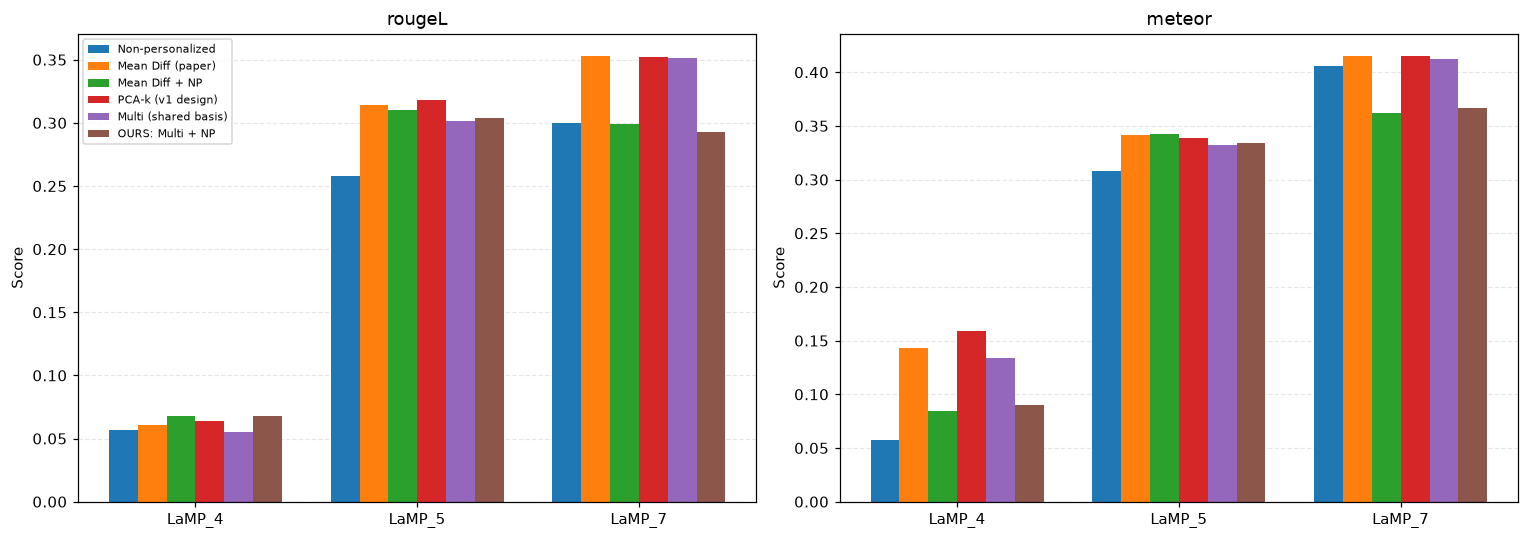

In [32]:

# Cell 6.3 — Bar chart (with the same modifications as Cell 6.1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
w = 0.13

for ax, met in zip(axes, ["rougeL", "meteor"]):
    for i, (c, lab) in enumerate(LABELS.items()):
        vals = []

        for t in TASKS:
            g = results_df[results_df.task == t]
            if len(g) == 0:
                vals.append(0)
                continue

            # Calculate the mean for the selected condition
            val = g[f"{met}_{c}"].mean()

            vals.append(val)

        ax.bar(
            np.arange(len(TASKS)) + (i - 2.5) * w,
            vals,
            w,
            label=lab
        )

    ax.set_xticks(range(len(TASKS)))
    ax.set_xticklabels(TASKS)
    ax.set_title(met)
    ax.set_ylabel("Score")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

axes[0].legend(fontsize=7)
plt.tight_layout()
plt.savefig(CKPT / "ablation_bar_chart.png", dpi=150)
plt.show()


In [28]:
# Cell 6.4 — Sweep of the shared-basis size r (proposal promised a sweep over the number of components).
# Runs on the TUNE users with shared_np's tuned (layer, alpha); pick R_SHARED from this, then re-run Parts 4.3/5.1 if you change it.
def r_sweep(task, rs=(1, 4, 8, 16, 32, 64)):
    res = {r: [] for r in rs}
    cfg = BEST[task]["shared_np"]; l, a = cfg["layer"], cfg["alpha"]
    for uid, u in tune_users[task].items():
        d = compute_user_deltas(uid, task, u["history"], MAX_HISTORY_PER_USER_BY_TASK[task], MAX_GEN_TOKENS)
        if d is None or uid not in POOL[task]["uids"]: continue
        idx = POOL[task]["uids"].index(uid)
        for r in rs:
            v = build_vectors(d[l], 1, POOL[task]["means"][l], idx, r=r)[0]["shared"]
            p = generate_with_steering(u["query_input"], l, v, a, True, MAX_GEN_TOKENS)
            sc = score_pair(p, u["query_gold"]); res[r].append(sum(sc) / 2)
    return {r: round(float(np.mean(v)), 4) for r, v in res.items() if v}
for t in TASKS: print(t, r_sweep(t))


[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

LaMP_4 {1: 0.0809, 4: 0.0761, 8: 0.0883, 16: 0.0831, 32: 0.0868, 64: 0.0848}


[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

LaMP_5 {1: 0.3994, 4: 0.3852, 8: 0.3702, 16: 0.3711, 32: 0.3786, 64: 0.3429}


[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=40) and `max_length`(=1024) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

LaMP_7 {1: 0.3559, 4: 0.3493, 8: 0.3496, 16: 0.3273, 32: 0.3381, 64: 0.3173}


In [33]:
# Cell 7.1 — Save
results_df.to_csv(CKPT / "full_results.csv", index=False)
ablation_table.to_csv(CKPT / "ablation_table.csv", index=False)
improvement_table.to_csv(CKPT / "improvement_table.csv", index=False)
print("saved to", CKPT.resolve())


saved to /home/user/stylevector_project/checkpoints_endterm_v2
